<a href="https://colab.research.google.com/github/bhagathcr/CAPSTONE-PROJECT-GROUP-5-/blob/main/Thermal_Aware_Power_Budgeting_Colab(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thermal-Aware Power Budgeting on a Chip
**Google Colab notebook:** steady-state thermal simulation, LP-based power allocation, and the four project plots.

Model inputs: 10 mm × 10 mm die, 40 × 40 grid, k = 150 W/(m·K), edge temperature = 300 K, four blocks at (10,10), (10,29), (29,10), (29,29), and total power budget = 5 W.

**Explicit assumptions:** die thickness = 0.5 mm and each source occupies a 3 × 3-node footprint, since these details were not specified in the project inputs. Results are outputs of this simplified model; they should not be presented as guaranteed target values. Symmetric blocks may lead to an optimized allocation close to uniform.


## 1. Imports and parameters

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import spsolve
from scipy.optimize import linprog

L = 10e-3
N = 40
k = 150.0
T_ambient = 300.0
die_thickness = 0.5e-3  # explicit assumption
P_budget = 5.0
source_radius = 1       # 3x3 source footprint
h = L / (N - 1)
n_int = N - 2
n_unknowns = n_int**2
block_centres = [(10,10), (10,29), (29,10), (29,29)]
block_names = ["Block 1", "Block 2", "Block 3", "Block 4"]
print(f"Grid spacing = {h*1e3:.4f} mm; interior unknowns = {n_unknowns}")


Grid spacing = 0.2564 mm; interior unknowns = 1444


## 2. Finite-difference model
For constant conductivity, the steady-state heat equation is \(\nabla^2 T=-Q/k\). The five-point stencil produces a sparse system for temperature rise above the 300 K boundary.


In [ ]:
def idx(i, j):
    return (i - 1) * n_int + (j - 1)

A = lil_matrix((n_unknowns, n_unknowns), dtype=float)
for i in range(1, N-1):
    for j in range(1, N-1):
        p = idx(i, j)
        A[p, p] = 4.0
        for ni, nj in [(i-1,j), (i+1,j), (i,j-1), (i,j+1)]:
            if 1 <= ni < N-1 and 1 <= nj < N-1:
                A[p, idx(ni, nj)] = -1.0
A = csr_matrix(A)

def source_cells(ci, cj):
    return [(i,j) for i in range(ci-source_radius, ci+source_radius+1)
                  for j in range(cj-source_radius, cj+source_radius+1)
                  if 1 <= i < N-1 and 1 <= j < N-1]

def response_map_per_watt(ci, cj):
    cells = source_cells(ci, cj)
    # Uniformly distribute 1 W across source-cell volume.
    q_per_watt = 1.0 / (len(cells) * h**2 * die_thickness)
    rhs = np.zeros(n_unknowns)
    for i,j in cells:
        rhs[idx(i,j)] += q_per_watt * h**2 / k
    rise = np.zeros((N,N))
    rise[1:-1,1:-1] = spsolve(A, rhs).reshape(n_int, n_int)
    return rise

response_maps = np.stack([response_map_per_watt(i,j) for i,j in block_centres])
def temperature_map(powers):
    return T_ambient + np.tensordot(np.asarray(powers), response_maps, axes=(0,0))
print("Response maps created:", response_maps.shape)


Response maps created: (4, 40, 40)


## 3. Uniform baseline (Plot 1)

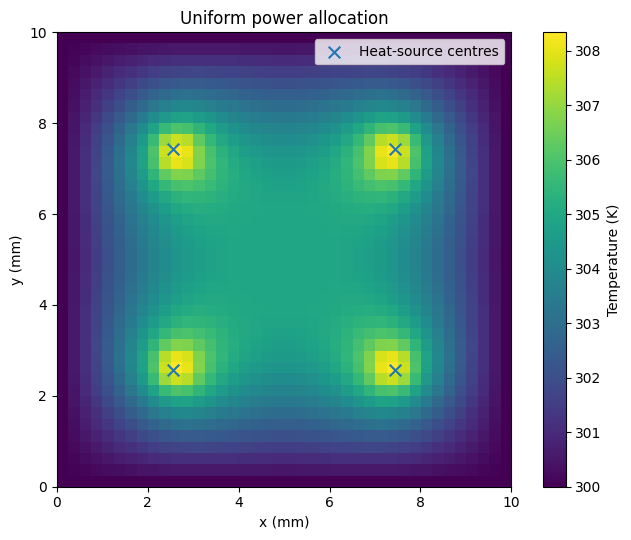

Uniform powers (W): [1.25 1.25 1.25 1.25]
Uniform peak temperature: 308.34 K


In [ ]:
uniform_power = np.full(4, P_budget/4)
T_uniform = temperature_map(uniform_power)
extent = [0, L*1e3, 0, L*1e3]
plt.figure(figsize=(7,5.5))
im = plt.imshow(T_uniform, origin="lower", extent=extent, aspect="equal")
plt.colorbar(im, label="Temperature (K)")
plt.scatter([j*h*1e3 for i,j in block_centres], [i*h*1e3 for i,j in block_centres],
            marker="x", s=70, label="Heat-source centres")
plt.title("Uniform power allocation"); plt.xlabel("x (mm)"); plt.ylabel("y (mm)")
plt.legend(); plt.tight_layout(); plt.show()
print("Uniform powers (W):", uniform_power)
print(f"Uniform peak temperature: {T_uniform.max():.2f} K")


## 4. Linear-programming optimization
Decision variables are \(q_1,q_2,q_3,q_4,t\). Minimize peak bound \(t\), subject to every grid temperature being ≤ \(t\), all powers being non-negative, and total power equalling the chosen budget.


In [ ]:
def optimize_allocation(total_power):
    R = response_maps.reshape(4, -1).T
    # T_ambient + Rq <= t  ->  Rq - t <= -T_ambient
    A_ub = np.hstack([R, -np.ones((N*N,1))])
    b_ub = np.full(N*N, -T_ambient)
    A_eq = np.array([[1.,1.,1.,1.,0.]])
    b_eq = np.array([total_power])
    bounds = [(0,None)]*4 + [(T_ambient,None)]
    objective = np.array([0.,0.,0.,0.,1.])
    result = linprog(objective, A_ub=A_ub, b_ub=b_ub,
                     A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    if not result.success:
        raise RuntimeError(result.message)
    powers = result.x[:4]
    return powers, temperature_map(powers), result

optimal_power, T_optimal, lp_result = optimize_allocation(P_budget)
print("Solver:", lp_result.message)
print("Optimized powers (W):", np.round(optimal_power, 4))
print(f"Optimized peak temperature: {T_optimal.max():.2f} K")


Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimized powers (W): [1.25 1.25 1.25 1.25]
Optimized peak temperature: 308.34 K


## 5. LP-optimized heatmap (Plot 2)

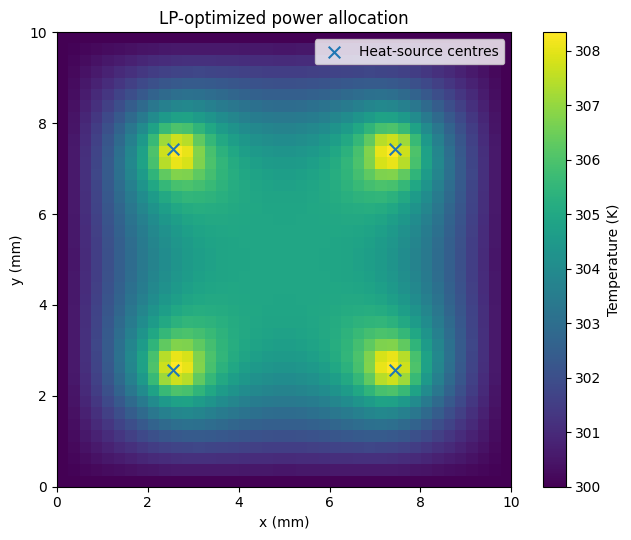

In [ ]:
plt.figure(figsize=(7,5.5))
im = plt.imshow(T_optimal, origin="lower", extent=extent, aspect="equal")
plt.colorbar(im, label="Temperature (K)")
plt.scatter([j*h*1e3 for i,j in block_centres], [i*h*1e3 for i,j in block_centres],
            marker="x", s=70, label="Heat-source centres")
plt.title("LP-optimized power allocation"); plt.xlabel("x (mm)"); plt.ylabel("y (mm)")
plt.legend(); plt.tight_layout(); plt.show()


## 6. Power allocation comparison (Plot 3)

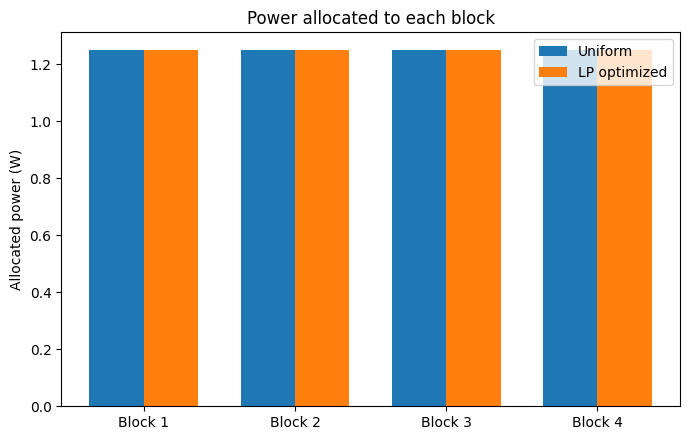

In [ ]:
x = np.arange(4); width = 0.36
plt.figure(figsize=(7,4.5))
plt.bar(x-width/2, uniform_power, width, label="Uniform")
plt.bar(x+width/2, optimal_power, width, label="LP optimized")
plt.xticks(x, block_names); plt.ylabel("Allocated power (W)")
plt.title("Power allocated to each block"); plt.legend()
plt.tight_layout(); plt.show()


## 7. Peak temperature vs power budget (Plot 4)

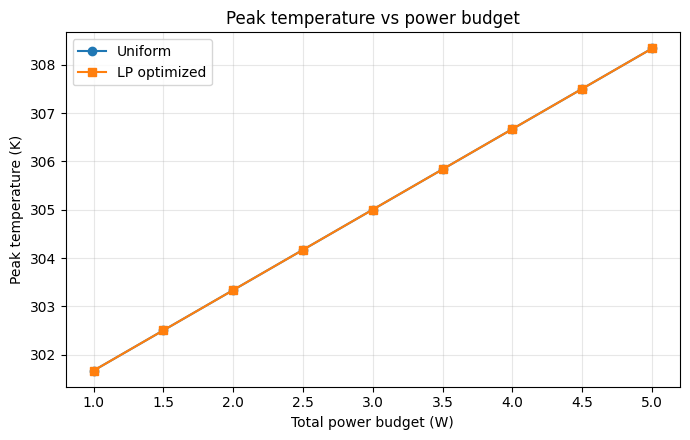

In [ ]:
budgets = np.linspace(1, 5, 9)
uniform_peaks, optimized_peaks = [], []
for budget in budgets:
    uniform_peaks.append(temperature_map(np.full(4, budget/4)).max())
    _, T_best, _ = optimize_allocation(budget)
    optimized_peaks.append(T_best.max())
plt.figure(figsize=(7,4.5))
plt.plot(budgets, uniform_peaks, marker="o", label="Uniform")
plt.plot(budgets, optimized_peaks, marker="s", label="LP optimized")
plt.xlabel("Total power budget (W)"); plt.ylabel("Peak temperature (K)")
plt.title("Peak temperature vs power budget"); plt.grid(True, alpha=.3)
plt.legend(); plt.tight_layout(); plt.show()


## 8. Validation and interpretation


In [ ]:
print("LP success:", lp_result.success)
print(f"Power sum = {optimal_power.sum():.6f} W (budget = {P_budget:.6f} W)")
print(f"Uniform peak = {T_uniform.max():.3f} K")
print(f"Optimized peak = {T_optimal.max():.3f} K")
print(f"Peak reduction = {T_uniform.max()-T_optimal.max():.3f} K")
assert lp_result.success
assert np.isclose(optimal_power.sum(), P_budget, atol=1e-6)
assert np.all(optimal_power >= -1e-8)
assert np.isfinite(T_uniform).all() and np.isfinite(T_optimal).all()
print("Basic validation checks passed.")


LP success: True
Power sum = 5.000000 W (budget = 5.000000 W)
Uniform peak = 308.340 K
Optimized peak = 308.340 K
Peak reduction = 0.000 K
Basic validation checks passed.


## 9. Talking points for the five members
1. **Member A — field model/PDE:** Fourier’s law and energy conservation lead to the steady-state Poisson equation.
2. **Member B — Laplace transform/thermal impedance:** thermal impedance is temperature response divided by power input in the transform domain. This notebook solves the steady-state case; a true transient model also needs thermal-capacitance information.
3. **Member C — finite differences:** the five-point stencil turns the PDE into a sparse linear system.
4. **Member D — optimization:** the LP minimizes the peak-temperature bound while distributing a fixed total power.
5. **Member E — Python pipeline:** create response maps, solve the LP, plot both heatmaps and comparisons, and run validation.

**Limitations:** simplified 2-D steady state, constant conductivity, ideal fixed-temperature edges, and assumed thickness/source footprint. Since the four blocks are identical and symmetrically placed, an optimized allocation close to uniform can be physically reasonable; do not force reference peak values if the model does not produce them.
